In [26]:
  import pandas as pd
import numpy as np
  import matplotlib.pyplot as plt
import seaborn as sns
  from scipy import stats

In [5]:
data = {
    'Student': ['A','B','C','D','E','F','G','H','I','J',
                'K','L','M','N','O','P','Q','R','S','T'],

    'Marks': [45, 50, 52, 48, 55, 60, 58, 62, 65, 59,
              61, 57, 63, 56, 54, 51, 49, 95, 100, 5]
}

df = pd.DataFrame(data)

print(df)

   Student  Marks
0        A     45
1        B     50
2        C     52
3        D     48
4        E     55
5        F     60
6        G     58
7        H     62
8        I     65
9        J     59
10       K     61
11       L     57
12       M     63
13       N     56
14       O     54
15       P     51
16       Q     49
17       R     95
18       S    100
19       T      5


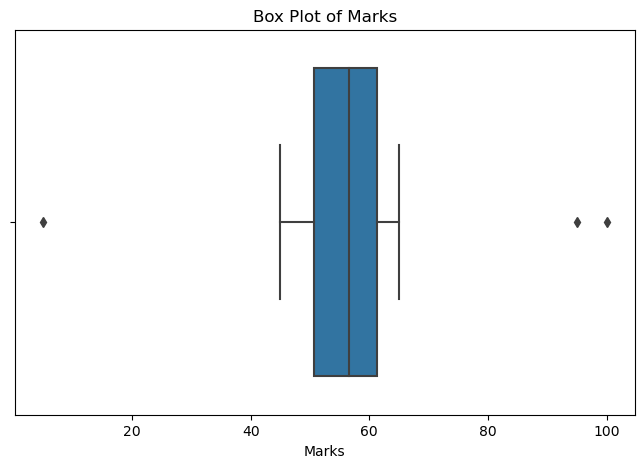

In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Marks'])
plt.title('Box Plot of Marks')
plt.xlabel('Marks')
plt.show()

In [7]:
q1=df['Marks'].quantile(0.25)
q3=df['Marks'].quantile(0.75)

print("Q1 =",q1)
print("Q3 =",q3)

Q1 = 50.75
Q3 = 61.25


In [8]:
iqr=q3-q1
print("IQR =",iqr)

IQR = 10.5


In [10]:
lower_limit=q1-1.5*iqr
upper_limit=q3+1.5*iqr

print("Lower Limit =",lower_limit)
print("Upper Limit =",upper_limit)

Lower Limit = 35.0
Upper Limit = 77.0


In [11]:
outliers=df[(df['Marks']<lower_limit) | (df['Marks']>upper_limit)]
print("Outliers:")
print(outliers)

Outliers:
   Student  Marks
17       R     95
18       S    100
19       T      5


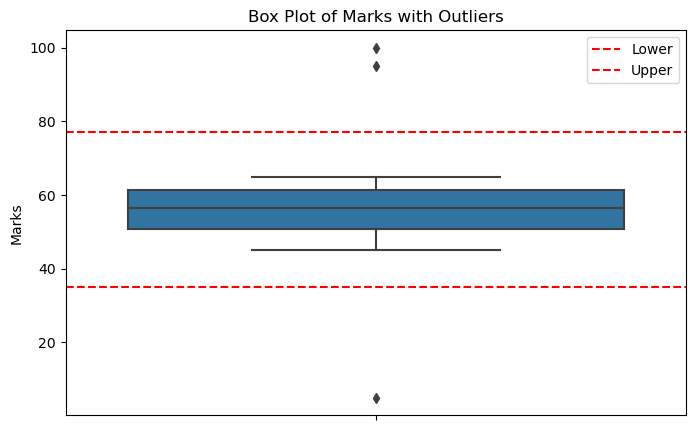

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Marks'])

plt.axhline(lower_limit, color='r', linestyle='--',label='Lower')
plt.axhline(upper_limit, color='r', linestyle='--',label='Upper')

plt.legend()

plt.title('Box Plot of Marks with Outliers')
plt.show()

In [13]:
df['Marks_IQR']=df['Marks'].clip(lower=lower_limit,upper=upper_limit)
print(df[['Marks','Marks_IQR']])

    Marks  Marks_IQR
0      45       45.0
1      50       50.0
2      52       52.0
3      48       48.0
4      55       55.0
5      60       60.0
6      58       58.0
7      62       62.0
8      65       65.0
9      59       59.0
10     61       61.0
11     57       57.0
12     63       63.0
13     56       56.0
14     54       54.0
15     51       51.0
16     49       49.0
17     95       77.0
18    100       77.0
19      5       35.0


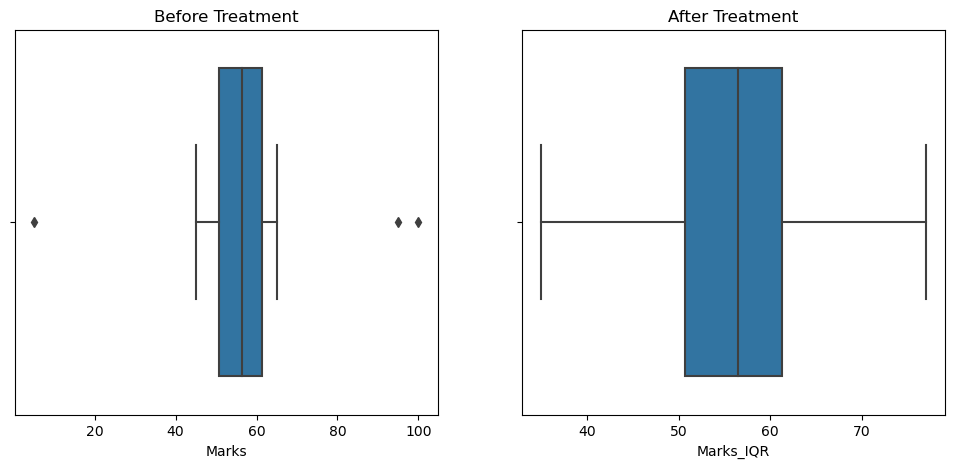

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(x=df['Marks'], ax=axes[0])
axes[0].set_title('Before Treatment')

sns.boxplot(x=df['Marks_IQR'], ax=axes[1])
axes[1].set_title('After Treatment')

plt.show()

In [15]:
df['Z_score'] = stats.zscore(df['Marks'])

print(df[['Marks', 'Z_score']])

    Marks   Z_score
0      45 -0.676200
1      50 -0.400200
2      52 -0.289800
3      48 -0.510600
4      55 -0.124200
5      60  0.151800
6      58  0.041400
7      62  0.262200
8      65  0.427800
9      59  0.096600
10     61  0.207000
11     57 -0.013800
12     63  0.317400
13     56 -0.069000
14     54 -0.179400
15     51 -0.345000
16     49 -0.455400
17     95  2.083800
18    100  2.359799
19      5 -2.884199


In [16]:
z_outliers = df[abs(df['Z_score']) > 3]

print("Outliers detected using Z-score:")
print(z_outliers)

df['Z_Outlier'] = abs(df['Z_score']) > 3

print(df[['Marks', 'Z_score', 'Z_Outlier']])

Outliers detected using Z-score:
Empty DataFrame
Columns: [Student, Marks, Marks_IQR, Z_score]
Index: []
    Marks   Z_score  Z_Outlier
0      45 -0.676200      False
1      50 -0.400200      False
2      52 -0.289800      False
3      48 -0.510600      False
4      55 -0.124200      False
5      60  0.151800      False
6      58  0.041400      False
7      62  0.262200      False
8      65  0.427800      False
9      59  0.096600      False
10     61  0.207000      False
11     57 -0.013800      False
12     63  0.317400      False
13     56 -0.069000      False
14     54 -0.179400      False
15     51 -0.345000      False
16     49 -0.455400      False
17     95  2.083800      False
18    100  2.359799      False
19      5 -2.884199      False


In [17]:
mean=df['Marks'].mean()
std=df['Marks'].std()

lower_z_limit=mean-3*std
upper_z_limit=mean+3*std

print("Lower Z-score Limit =",lower_z_limit)
print("Upper Z-score Limit =",upper_z_limit)

Lower Z-score Limit = 1.4902946847626737
Upper Z-score Limit = 113.00970531523733


In [18]:
df['Marks_Z_Capped'] = df['Marks'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit
)
print(df[['Marks', 'Marks_Z_Capped']])

    Marks  Marks_Z_Capped
0      45              45
1      50              50
2      52              52
3      48              48
4      55              55
5      60              60
6      58              58
7      62              62
8      65              65
9      59              59
10     61              61
11     57              57
12     63              63
13     56              56
14     54              54
15     51              51
16     49              49
17     95              95
18    100             100
19      5               5


KeyError: "['Marks_IQR_Capped'] not in index"